# Relazione sul progetto
Alessio Camerano
Matricola: 1044444

## Struttura del progetto

Il progetto e'stato diviso in sottocartelle per separare in modo netto motori di ricerca, euristica, domini e strumenti di supporto.

```text
progetto prolog/
├── src/prolog/
│   ├── algoritmi/
│   │   ├── aStar.pl
│   │   └── idaStar.pl
│   ├── euristica/
│   │   └── euristica.pl
│   ├── domini/
│   │   ├── labirinto/
│   │   │   ├── labirinto.pl
│   │   │   └── labirinto_azioni.pl
│   │   └── puzzle/
│   │       ├── puzzle.pl
│   │       └── puzzle_azioni.pl
│   └── app/
│       └── main.pl
├── tools/python/
│   ├── genera_prolog_maze.py
│   └── visualizza_risultati.py
└── docs/
    └── relazione_progetto.ipynb
```

I file Python non fanno parte del requisito originario del progetto: sono stati creati con l'aiuto di Copilot per testare, generare il labirinto e visualizzare i risultati in modo piu' leggibile.

## Cosa si studia

Il progetto confronta due strategie di ricerca su spazio degli stati.

- **aStar** usa una frontiera ordinata secondo $f(n) = g(n) + h(n)$.
- **idaStar** effettua una profondita' iterativa con soglie crescenti sul valore $f(n)$.

L'euristica e' basata sulla distanza di Manhattan. Nel labirinto viene usata la distanza Manhattan dal nodo corrente al goal piu' vicino, mentre nel puzzle dell'8 la somma delle distanze Manhattan delle tessere dal loro posto finale, ignorando lo zero.

## Come e' composto il progetto Prolog

Il codice Prolog e' separato per responsabilita':

- `aStar.pl` e `idaStar.pl` contengono i motori di ricerca.
- `euristica.pl` contiene la funzione euristica condivisa.
- `labirinto.pl` e `labirinto_azioni.pl` descrivono il dominio del labirinto e le mosse ammissibili.
- `puzzle.pl` e `puzzle_azioni.pl` descrivono lo stato iniziale/finale e le mosse del puzzle dell'8.
- `main.pl` resta il punto di ingresso Prolog.

## Risultati sperimentali

Qui sotto sono riportate le esecuzioni ottenute su un labirinto 200x200 e sul classico 8-puzzle

| Dominio | Algoritmo | Costo | Azioni | Tempo | Stack MB | Picco RAM MB |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| Labirinto | A* | 3206 | 3206 | 2.443 s | 20.16 | 33.33 |
| Labirinto | IDA* | 3206 | 3206 | 186.794 s | 3.52 | 18.07 |
| Puzzle | A* | 27 | 27 | 0.318 s | 20.20 | 26.86 |
| Puzzle | IDA* | 27 | 27 | 0.513 s | 0.35 | 18.11 |

# Confronto Prestazionale: A* vs IDA*

Il comportamento di **A\*** e **IDA\*** evidenzia un chiaro e immediato *trade-off* tra tempo di calcolo e memoria allocata, le cui prestazioni variano drasticamente a seconda del dominio applicativo.

### 1. Il Dominio del Labirinto
Nel **labirinto**, un grafo esteso e ricco di percorsi alternativi:
* **A\*** minimizza il tempo di esecuzione bloccando la ri-esplorazione degli stati già visitati, una rapidità che richiede tuttavia un carico di RAM significativo per sostenere la frontiera.
* **IDA\*** si rivela la scelta ottimale per mantenere un consumo di memoria estremamente contenuto, accettando però un forte rallentamento temporale dovuto alla continua riespansione degli stessi nodi a ogni aumento di soglia.

### 2. Il Dominio del Gioco dell'8
Nel **puzzle dell'8**, caratterizzato da uno spazio di ricerca più stretto, questo divario si riduce:
* Entrambe le tecniche identificano agevolmente la soluzione ottima.
* **A\*** si conferma come l'opzione più rapida in assoluto.
* **IDA\*** si consolida come la variante strutturalmente più leggera ed efficiente sul piano della RAM.

## Labirinto: soluzione calcolata dai due algoritmi

La cella seguente mostra il labirinto utilizzato per lo studio con anche la soluzione trovata dai 2 algoritmi.

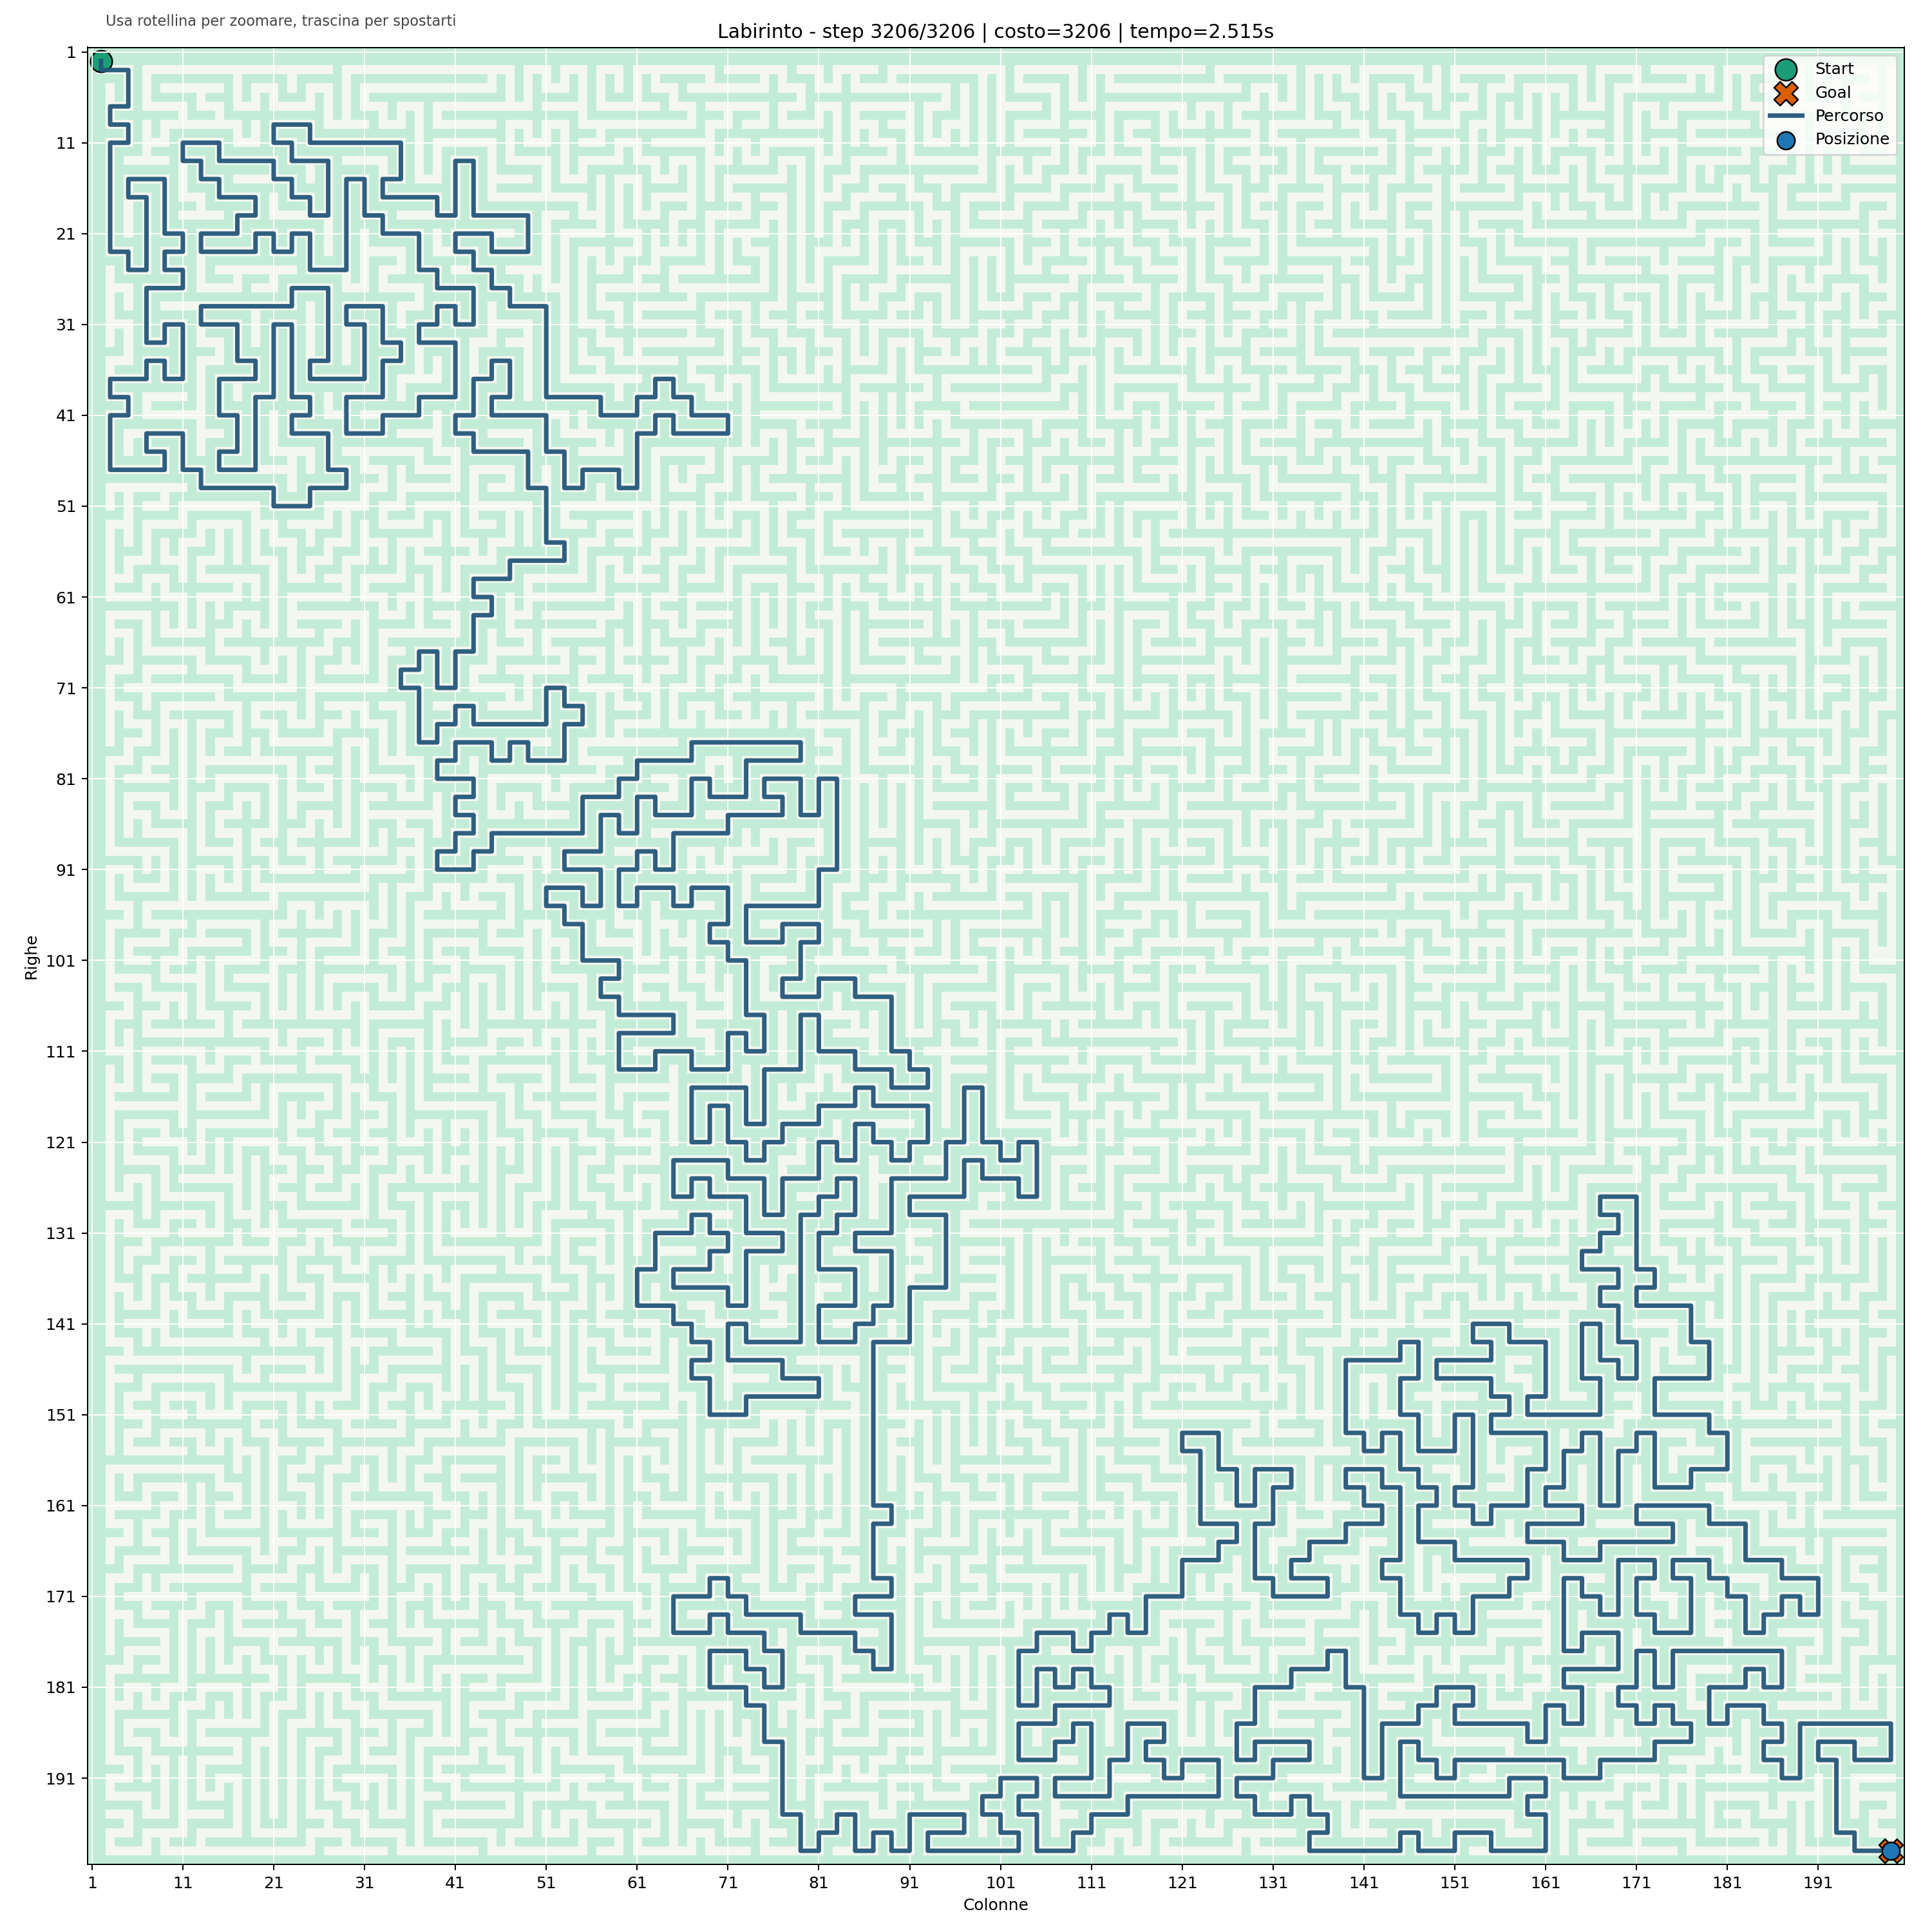

In [3]:
from pathlib import Path
import subprocess
import sys

from IPython.display import Image, display

project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / 'src/prolog/app/main.pl').exists()
)
out_dir = project_root / 'docs/figures'
out_dir.mkdir(parents=True, exist_ok=True)
script = project_root / 'tools/python/visualizza_risultati.py'

outfile = out_dir / 'labirinto_astar.png'
subprocess.run(
    [sys.executable, str(script), '--domain', 'labirinto', '--algo', 'astar', '--save', str(outfile)],
    check=True,
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
)

display(Image(filename=str(outfile)))
